# 03. Deployment: sơ đồ, kiểm tra mô hình và kiểm thử ứng dụng
Notebook này chuẩn bị và kiểm tra phần **deploy**:
1. Vẽ sơ đồ kiến trúc triển khai
2. Nạp lại mô hình đã lưu, đo kích thước và tốc độ dự đoán
3. Thử vài giao dịch mẫu
4. Kiểm thử tự động ứng dụng web Streamlit (`app.py`)

> Cần chạy `02_Modelling_and_Evaluation.ipynb` trước để có thư mục `model/`.

**Đầu ra:** `figures/11_architecture.png`, `deploy_check.json`.

In [4]:
import json
import os
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

import fraud_features  # noqa: F401  (joblib cần module này để nạp hàm add_features)
from fraud_features import RAW_COLUMNS

%matplotlib inline
os.makedirs("figures", exist_ok=True)

## 1. Sơ đồ kiến trúc triển khai
Người dùng → ứng dụng Streamlit → pipeline đã lưu → so sánh xác suất với ngưỡng → kết quả.

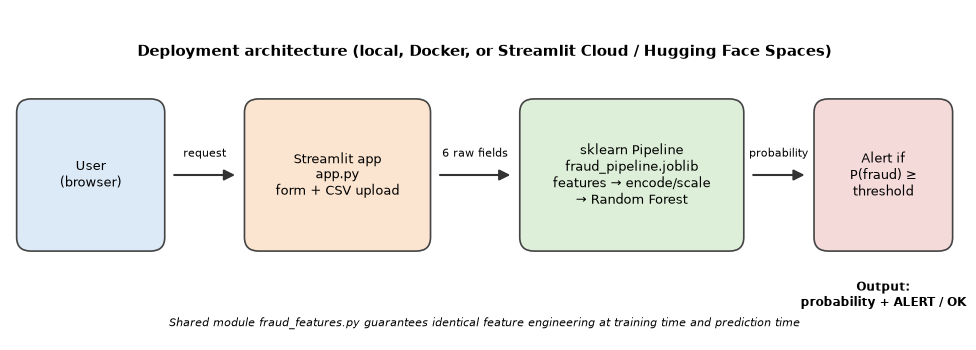

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.set_xlim(0, 100)
ax.set_ylim(0, 36)
ax.axis("off")

y0, h = 10, 16
boxes = [  # (x, width, text, colour)
    (1, 15, "User\n(browser)", "#DCE9F7"),
    (25, 19, "Streamlit app\napp.py\nform + CSV upload", "#FBE5D0"),
    (54, 23, "sklearn Pipeline\nfraud_pipeline.joblib\nfeatures → encode/scale\n→ Random Forest", "#DDEFD8"),
    (85, 14, "Alert if\nP(fraud) ≥\nthreshold", "#F5DADA"),
]
for x, w, text, color in boxes:
    ax.add_patch(FancyBboxPatch((x, y0), w, h, boxstyle="round,pad=0.3,rounding_size=1.5", fc=color, ec="#444", lw=1.2))
    ax.text(x + w / 2, y0 + h / 2, text, ha="center", va="center", fontsize=9)


def arrow(x1, x2, label=""):
    ax.add_patch(FancyArrowPatch((x1, y0 + h / 2), (x2, y0 + h / 2), arrowstyle="-|>", mutation_scale=16, lw=1.5, color="#333"))
    if label:
        ax.text((x1 + x2) / 2, y0 + h / 2 + 2, label, ha="center", fontsize=8)


arrow(17, 24, "request")
arrow(45, 53, "6 raw fields")
arrow(78, 84, "probability")
ax.text(92, 6.5, "Output:\nprobability + ALERT / OK", ha="center", va="top", fontsize=8.5, fontweight="bold")
ax.text(50, 31, "Deployment architecture (local, Docker, or Streamlit Cloud / Hugging Face Spaces)",
        ha="center", fontsize=11, fontweight="bold")
ax.text(50, 1.5, "Shared module fraud_features.py guarantees identical feature engineering at training time and prediction time",
        ha="center", fontsize=8, style="italic")
plt.tight_layout()
plt.savefig("figures/11_architecture.png", dpi=150)
plt.show()

## 2. Nạp mô hình đã lưu, đo kích thước và tốc độ
Một ứng dụng thật phải trả lời nhanh. Ta đo thời gian dự đoán cho 1 giao dịch (như khi người dùng bấm nút) và cho 10.000 giao dịch (như khi tải file CSV).

In [6]:
path = "model/fraud_pipeline.joblib"
pipe = joblib.load(path)
meta = json.load(open("model/metadata.json", encoding="utf-8"))
df = pd.read_csv("Synthetic_Financial_datasets_log.csv", encoding="utf-8-sig")

row = df[RAW_COLUMNS].iloc[[0]]
for _ in range(5):          # chạy khởi động để không tính lần đầu chậm
    pipe.predict_proba(row)

times = []
for i in range(100):
    r = df[RAW_COLUMNS].iloc[[i]]
    t0 = time.perf_counter()
    pipe.predict_proba(r)
    times.append((time.perf_counter() - t0) * 1000)

batch = df[RAW_COLUMNS].iloc[:10000]
t0 = time.perf_counter()
pipe.predict_proba(batch)
batch_s = time.perf_counter() - t0

print(f"Kích thước file mô hình : {os.path.getsize(path) / 1e6:.1f} MB")
print(f"1 giao dịch             : trung bình {np.mean(times):.1f} ms (p95 {np.percentile(times, 95):.1f} ms)")
print(f"10.000 giao dịch        : {batch_s:.2f} s")

Kích thước file mô hình : 0.3 MB
1 giao dịch             : trung bình 6.2 ms (p95 8.4 ms)
10.000 giao dịch        : 0.01 s


## 3. Thử vài giao dịch mẫu
Ba ví dụ: một chuyển khoản đáng ngờ (rút sạch tài khoản), một thanh toán bình thường, một rút tiền bình thường. Kỳ vọng: giao dịch đầu bị cảnh báo, hai giao dịch sau thì không.

In [7]:
examples = {
    "suspicious TRANSFER (balance emptied)": dict(type="TRANSFER", amount=181.0, oldbalanceOrg=181.0, newbalanceOrig=0.0,
                                                  oldbalanceDest=0.0, newbalanceDest=0.0),
    "normal PAYMENT": dict(type="PAYMENT", amount=9839.64, oldbalanceOrg=170136.0, newbalanceOrig=160296.36,
                           oldbalanceDest=0.0, newbalanceDest=0.0),
    "normal CASH_OUT": dict(type="CASH_OUT", amount=229133.94, oldbalanceOrg=15325.0, newbalanceOrig=0.0,
                            oldbalanceDest=5083.0, newbalanceDest=51513.44),
}
ex_out = {}
for k, v in examples.items():
    p = float(pipe.predict_proba(pd.DataFrame([v])[RAW_COLUMNS])[0, 1])
    ex_out[k] = {"input": v, "probability": p, "alert": bool(p >= meta["threshold_f1"])}
    print(f"{k:40s} P(fraud) = {p:.4f} -> {'ALERT' if ex_out[k]['alert'] else 'OK'}")

out = {
    "model_file_mb": round(os.path.getsize(path) / 1e6, 1),
    "single_row_latency_ms_mean": round(float(np.mean(times)), 1),
    "single_row_latency_ms_p95": round(float(np.percentile(times, 95)), 1),
    "batch_10000_rows_seconds": round(batch_s, 2),
    "examples": ex_out,
}
with open("deploy_check.json", "w", encoding="utf-8") as fh:
    json.dump(out, fh, ensure_ascii=False, indent=2)
print("\nĐã lưu deploy_check.json")

suspicious TRANSFER (balance emptied)    P(fraud) = 0.9978 -> ALERT
normal PAYMENT                           P(fraud) = 0.0000 -> OK
normal CASH_OUT                          P(fraud) = 0.0001 -> OK

Đã lưu deploy_check.json


## 4. Kiểm thử tự động ứng dụng Streamlit
Dùng `streamlit.testing` để mở ứng dụng `app.py` **không cần trình duyệt**, chọn ví dụ, bấm nút và kiểm tra kết quả hiển thị. Nếu một `assert` sai, notebook sẽ báo lỗi.

In [8]:
from streamlit.testing.v1 import AppTest

at = AppTest.from_file(os.path.abspath("app.py"), default_timeout=60).run()  # cần đường dẫn tuyệt đối trong notebook
assert not at.exception, "App bị lỗi khi tải trang"

# Ví dụ đáng ngờ -> phải có cảnh báo (st.error)
at.selectbox[0].select("Suspicious transaction (account emptied)").run()
at.button[0].click().run()
assert not at.exception
assert len(at.error) == 1 and "ALERT" in at.error[0].value, "Ví dụ đáng ngờ phải bị cảnh báo"
print("Suspicious ->", at.error[0].value)

# Ví dụ bình thường -> phải báo OK (st.success)
at.selectbox[0].select("Normal payment").run()
at.button[0].click().run()
assert not at.exception
assert len(at.success) == 1 and "OK" in at.success[0].value, "Giao dịch bình thường phải báo OK"
print("Normal     ->", at.success[0].value)
print("\nCả hai bài kiểm thử đều đạt.")

2026-10-15 19:07:41.350 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Suspicious -> ALERT: this transaction shows signs of fraud
Normal     -> OK: this transaction looks normal

Cả hai bài kiểm thử đều đạt.


## 5. Chạy ứng dụng thật
Mở terminal (không phải notebook) trong thư mục dự án và chạy:
```bash
streamlit run app.py
```
Rồi mở http://localhost:8501. Chụp ảnh màn hình để chèn vào mục 6.3 của báo cáo.

Chạy bằng Docker:
```bash
docker build -t fraud-app .
docker run -p 8501:8501 fraud-app
```